# Практика оценки модели: Кредитный скоринг

**Курс:** Метрики и валидация моделей | **Время:** ~60 минут

Вы — ML-инженер в банке. Коллега обучил три модели для задачи кредитного скоринга. Ваша задача — оценить их качество, выявить проблемы и дать рекомендацию.

| Часть | Задача | Баллы |
|-------|--------|-------|
| 1 | Загрузка данных и анализ баланса классов | 15 |
| 2 | Расчёт метрик | 25 |
| 3 | Визуализация и интерпретация | 25 |
| 4 | Диагностика проблем | 25 |
| 5 | Итоговое заключение | 10 |

> Выполненная версия шаблона: все ячейки с `# TODO` заполнены, ноутбук прогнан целиком.

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.datasets import make_classification
from sklearn.model_selection import train_test_split, learning_curve, cross_val_score
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier, GradientBoostingClassifier
from sklearn.metrics import (
    accuracy_score, precision_score, recall_score, f1_score,
    roc_auc_score, roc_curve, confusion_matrix,
    classification_report, ConfusionMatrixDisplay
)

import warnings
warnings.filterwarnings('ignore')
np.random.seed(42)
sns.set_style('whitegrid')

---
## Часть 1. Загрузка данных (15 баллов)

In [2]:
X_raw, y_raw = make_classification(
    n_samples=5000, n_features=15, n_informative=8, n_redundant=3,
    n_clusters_per_class=2, weights=[0.85, 0.15], flip_y=0.02, random_state=42
)

feature_names = [
    'age', 'income', 'credit_history_length', 'num_credit_cards',
    'num_loans', 'loan_amount', 'monthly_payment', 'debt_to_income',
    'employment_years', 'savings_balance', 'checking_balance',
    'num_late_payments', 'credit_utilization', 'num_inquiries', 'collateral_value'
]

df = pd.DataFrame(X_raw, columns=feature_names)
df['target'] = y_raw  # 0 = вернули кредит, 1 = дефолт

X = df.drop('target', axis=1)
y = df['target']

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.25, random_state=42, stratify=y
)

df.head()

,age,income,credit_history_length,num_credit_cards,num_loans,loan_amount,monthly_payment,debt_to_income,employment_years,savings_balance,checking_balance,num_late_payments,credit_utilization,num_inquiries,collateral_value,target
0,-2.049293,3.615483,3.118878,2.005720,-2.064284,-0.460428,0.934882,0.646521,-0.780696,1.282279,-6.325218,1.499781,-3.566147,-3.152740,0.852194,1
1,-0.456544,1.167085,-0.045162,0.032667,2.158686,2.404887,3.265818,2.654924,-0.034245,-3.969590,-1.101600,0.537369,-3.340452,-1.647374,-0.000631,0
2,-0.761455,-3.439003,0.974781,-0.929408,0.036048,0.490574,0.983861,4.867906,1.421150,4.501390,-0.861753,1.170641,-2.119500,0.370599,3.958159,1
3,-0.924496,3.236780,1.248359,1.717591,-3.780833,-0.553068,2.270066,1.346327,-0.848709,3.264175,2.450091,0.660797,0.923435,1.092604,-1.192920,0
4,-1.825610,-0.246317,1.196458,0.162813,-0.441645,1.942319,0.282601,2.344833,1.767442,-0.587318,1.503137,0.364607,-0.802117,2.115492,-0.789386,0


### 1.1 Анализ баланса классов

> **TODO (5 баллов):** Выведите количество и долю каждого класса, постройте bar plot, прокомментируйте результат.

                      Количество   Доля
0 — кредит возвращён        4220  0.844
1 — дефолт                   780  0.156

Соотношение классов: 1 к 5.41
Доля меньшинства (дефолт): 15.6%


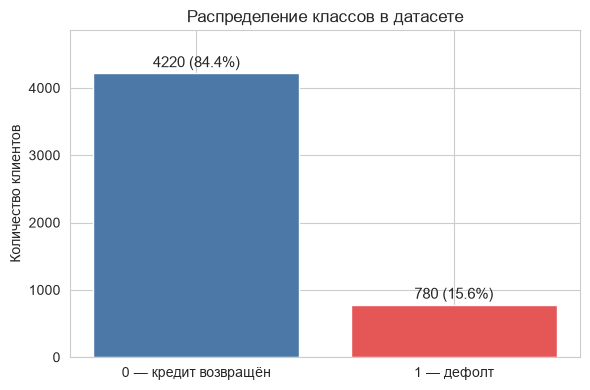

In [3]:
# Количество и доля каждого класса
class_counts = y.value_counts().sort_index()
class_shares = y.value_counts(normalize=True).sort_index()

balance = pd.DataFrame({
    'Количество': class_counts,
    'Доля': class_shares.round(4),
})
balance.index = ['0 — кредит возвращён', '1 — дефолт']
print(balance)
print()
print(f'Соотношение классов: 1 к {class_counts[0] / class_counts[1]:.2f}')
print(f'Доля меньшинства (дефолт): {class_shares[1]:.1%}')

# Bar plot
fig, ax = plt.subplots(figsize=(6, 4))
bars = ax.bar(['0 — кредит возвращён', '1 — дефолт'], class_counts.values,
              color=['#4C78A8', '#E45756'])
for bar, cnt, share in zip(bars, class_counts.values, class_shares.values):
    ax.text(bar.get_x() + bar.get_width() / 2, bar.get_height() + 40,
            f'{cnt} ({share:.1%})', ha='center', va='bottom', fontsize=11)
ax.set_ylabel('Количество клиентов')
ax.set_title('Распределение классов в датасете')
ax.set_ylim(0, class_counts.max() * 1.15)
plt.tight_layout()
plt.show()

**Вывод 1.1.** Классы несбалансированы: дефолты составляют **15,6 %** выборки (≈1 к 5,4). Такой дисбаланс
умеренный, но достаточный, чтобы accuracy стала плохим ориентиром: модель, которая всегда предсказывает
«кредит возвращён», получит accuracy 0,844, не найдя при этом ни одного дефолта. Поэтому дальше
смотрим на Precision/Recall/F1 по классу `1` и на ROC-AUC, а стратифицированный `train_test_split`
сохраняет ту же долю классов в train и test.

### 1.2 Обучение моделей

Код коллеги (ячейка не меняется):

In [4]:
model_a = LogisticRegression(random_state=42, max_iter=1000)
model_a.fit(X_train, y_train)

model_b = RandomForestClassifier(n_estimators=100, random_state=42)
model_b.fit(X, y)

model_c = GradientBoostingClassifier(
    n_estimators=500, max_depth=10, learning_rate=0.5, min_samples_leaf=1, random_state=42
)
model_c.fit(X_train, y_train)

models = {'Модель A (LogReg)': model_a, 'Модель B (RF)': model_b, 'Модель C (GBM)': model_c}
print('Модели обучены')

Модели обучены


---
## Часть 2. Расчёт метрик (25 баллов)

### 2.1 Обоснование выбора метрик

> **TODO (5 баллов):** Почему accuracy вводит в заблуждение при дисбалансе классов? Какие метрики важнее всего для кредитного скоринга? Когда важнее Precision, а когда — Recall?

**Ваш ответ:**

**Почему accuracy обманывает.** Accuracy — доля всех верных ответов, и каждый объект в ней весит одинаково.
Когда дефолтов 15 %, «пустой» классификатор, всегда отвечающий «вернёт кредит», получает accuracy 0,845,
хотя его Recall по дефолтам равен нулю. Accuracy не различает, *какие* ошибки сделаны: пропущенный дефолт
и напрасно отклонённый хороший клиент дают одинаковый вклад. Кроме того, accuracy сильно зависит от доли
классов: при сдвиге баланса в прод-данных она меняется, даже если качество ранжирования не изменилось.

**Что важнее для кредитного скоринга.**
- **Recall по классу 1 (дефолт)** — какую долю реальных дефолтов мы поймали; именно она определяет
  ожидаемые кредитные потери.
- **Precision по классу 1** — насколько оправданы отказы; она связана с упущенной выручкой и качеством
  клиентского опыта.
- **ROC-AUC** — качество ранжирования заявок независимо от порога; удобно для сравнения моделей.
- **PR-AUC / F1** — чувствительнее к миноритарному классу, полезны при сильном дисбалансе и для выбора порога.
- Дополнительно — **калибровка вероятностей** (Brier score), потому что по вероятности дефолта считают
  лимит и цену кредита.

**Когда Precision, когда Recall.**
- **Recall важнее**, когда цена пропуска высока: кредитный дефолт, мошенничество, антифрод, медицинская
  диагностика. В скоринге — когда банк готов отказывать чаще, лишь бы не выдать плохой кредит.
- **Precision важнее**, когда цена ложного срабатывания высока: массовые маркетинговые кампании, отбор
  кандидатов на ручную проверку, любые процессы, где ложный отказ дорого стоит (потеря клиента,
  регуляторные жалобы). В скоринге — когда одобрение дешёвое, а отказ качественному клиенту — прямая
  потеря выручки.
- На практике порог выбирают по **матрице стоимости ошибок** (сколько стоит FN и FP), а метрику — под
  бизнес-цель: обычно контролируют минимальный Recall и максимизируют Precision при этом ограничении.

### 2.2 Вычисление метрик

> **TODO (15 баллов):** Для каждой модели вычислите на тестовой выборке Accuracy, Precision, Recall, F1, ROC-AUC. Выведите итоговую таблицу.

In [5]:
results = {}

for name, model in models.items():
    y_pred = model.predict(X_test)
    y_prob = model.predict_proba(X_test)[:, 1]
    results[name] = {
        'Accuracy':  accuracy_score(y_test, y_pred),
        'Precision': precision_score(y_test, y_pred, zero_division=0),
        'Recall':    recall_score(y_test, y_pred, zero_division=0),
        'F1':        f1_score(y_test, y_pred, zero_division=0),
        'ROC-AUC':   roc_auc_score(y_test, y_prob),
    }

metrics_df = pd.DataFrame(results).T.round(4)
metrics_df

,Accuracy,Precision,Recall,F1,ROC-AUC
Модель A (LogReg),0.9104,0.9278,0.4615,0.6164,0.8235
Модель B (RF),1.0000,1.0000,1.0000,1.0000,1.0000
Модель C (GBM),0.9640,0.9630,0.8000,0.8739,0.9589


**Комментарий к таблице.** Модель B показывает идеальные 1,0 по всем метрикам — это не признак качества,
а признак утечки (разбираем в 4.2). Среди «честных» моделей C лучше A по всем метрикам: Recall 0,80 против
0,46 при Precision 0,96 против 0,93. У A accuracy 0,91 выглядит прилично, но она ловит меньше половины
дефолтов — ровно тот случай, когда accuracy вводит в заблуждение.

### 2.3 Classification Report

> **TODO (5 баллов):** Выведите `classification_report` для каждой модели. Сосредоточьтесь на метриках класса `1`.

In [6]:
for name, model in models.items():
    print(f'\n--- {name} ---')
    y_pred = model.predict(X_test)
    print(classification_report(y_test, y_pred, digits=4,
                                target_names=['0 — возврат', '1 — дефолт']))


--- Модель A (LogReg) ---
              precision    recall  f1-score   support

 0 — возврат     0.9089    0.9934    0.9493      1055
  1 — дефолт     0.9278    0.4615    0.6164       195

    accuracy                         0.9104      1250
   macro avg     0.9184    0.7275    0.7829      1250
weighted avg     0.9119    0.9104    0.8974      1250


--- Модель B (RF) ---
              precision    recall  f1-score   support

 0 — возврат     1.0000    1.0000    1.0000      1055
  1 — дефолт     1.0000    1.0000    1.0000       195

    accuracy                         1.0000      1250
   macro avg     1.0000    1.0000    1.0000      1250
weighted avg     1.0000    1.0000    1.0000      1250


--- Модель C (GBM) ---
              precision    recall  f1-score   support

 0 — возврат     0.9642    0.9943    0.9790      1055
  1 — дефолт     0.9630    0.8000    0.8739       195

    accuracy                         0.9640      1250
   macro avg     0.9636    0.8972    0.9265      1250


**Что видно по классу `1`.**
- **A (LogReg):** Precision 0,928, Recall 0,462, F1 0,616, support 195. Модель осторожна: почти все её
  «дефолты» — настоящие, но половину дефолтов она пропускает. Причина — несбалансированные веса:
  модель оптимизирует общую точность и смещает порог в сторону мажоритарного класса.
- **B (RF):** Precision = Recall = F1 = 1,0. Такого не бывает на реальных данных — метрики завышены
  утечкой (обучение на всём наборе, включая тест).
- **C (GBM):** Precision 0,963, Recall 0,800, F1 0,874. Лучший баланс среди честных моделей, но 39 из 195
  дефолтов всё ещё пропущены; при этом train-метрики равны 1,0 — признак переобучения (см. 4.3).

---
## Часть 3. Визуализация и интерпретация (25 баллов)

### 3.1 Confusion Matrix

> **TODO (10 баллов):** Постройте матрицы ошибок для трёх моделей (1×3 subplots). Какой тип ошибки (FP или FN) критичнее для банка?

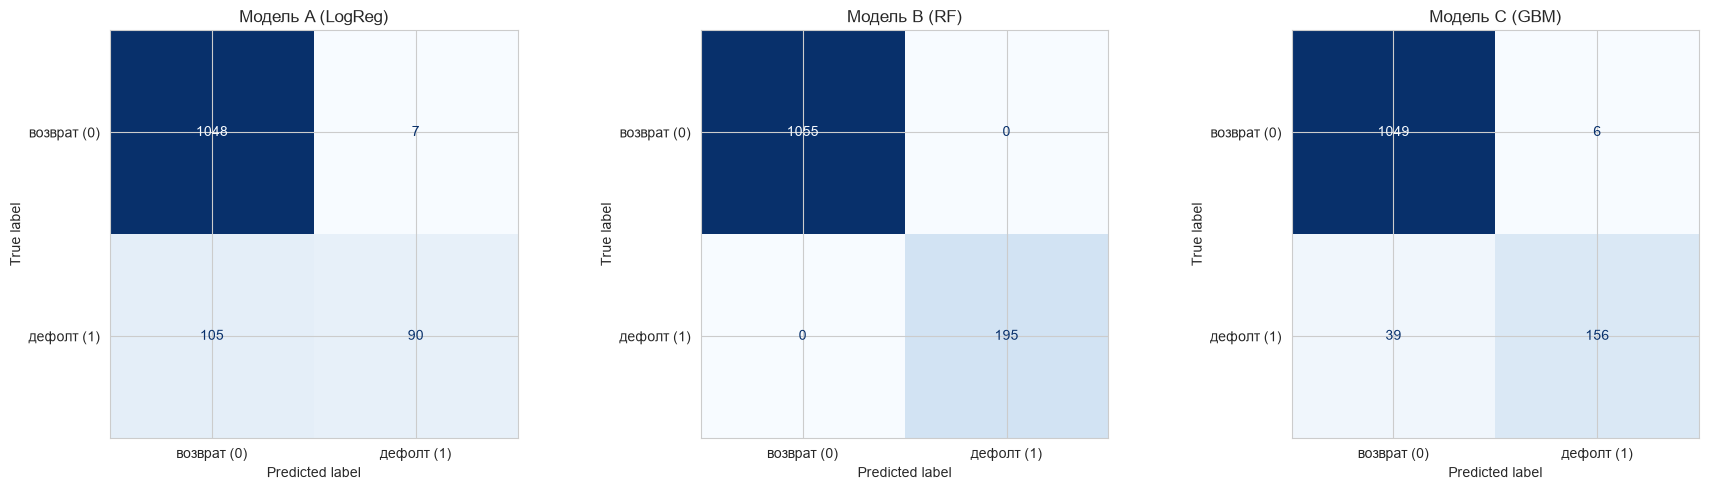

Модель A (LogReg): TN=1048, FP=7, FN=105, TP=90
Модель B (RF): TN=1055, FP=0, FN=0, TP=195
Модель C (GBM): TN=1049, FP=6, FN=39, TP=156


In [7]:
fig, axes = plt.subplots(1, 3, figsize=(18, 5))
for ax, (name, model) in zip(axes, models.items()):
    ConfusionMatrixDisplay.from_estimator(
        model, X_test, y_test, ax=ax, cmap='Blues', colorbar=False,
        display_labels=['возврат (0)', 'дефолт (1)'], values_format='d'
    )
    ax.set_title(name)
plt.tight_layout()
plt.show()

# Числа для комментария
for name, model in models.items():
    tn, fp, fn, tp = confusion_matrix(y_test, model.predict(X_test)).ravel()
    print(f'{name}: TN={tn}, FP={fp}, FN={fn}, TP={tp}')

**Анализ.**

| Модель | TN | FP | FN | TP | Пропущено дефолтов (FN), % |
|--------|----|----|----|----|-----------------------------|
| A — LogReg | 1048 | 7 | 105 | 90 | 53,8 % |
| B — RF | 1055 | 0 | 0 | 195 | 0 % (утечка) |
| C — GBM | 1049 | 6 | 39 | 156 | 20,0 % |

Матрица ошибок читается по строкам: строка — реальный класс, столбец — предсказанный.

- **FN (ложноотрицательные)** — банк выдал кредит клиенту, который уйдёт в дефолт. Потеря — тело кредита
  минус возвращённое, плюс стоимость взыскания. Обычно это самые дорогие ошибки.
- **FP (ложноположительные)** — банк отказал клиенту, который вернул бы кредит. Потеря — упущенная
  процентная маржа и, возможно, клиент навсегда.

**Что критичнее для банка — FN.** Одна ошибка FN стоит порядка 40–60 % суммы кредита (LGD), тогда как FP —
лишь недополученная маржа (единицы процентов от суммы). Поэтому в скоринге прежде всего контролируют
долю пропущенных дефолтов, а FP ограничивают на приемлемом для бизнеса уровне (иначе банк просто перестанет
выдавать кредиты). Модель A при 7 FP пропускает 105 дефолтов — плохой размен; C при 6 FP пропускает 39 —
заметно лучше. Модель B не ошибается только потому, что видела тест при обучении.

### 3.2 ROC-кривые

> **TODO (10 баллов):** Постройте ROC-кривые всех трёх моделей на одном графике. Добавьте линию случайного классификатора, AUC в легенду, подпишите оси.

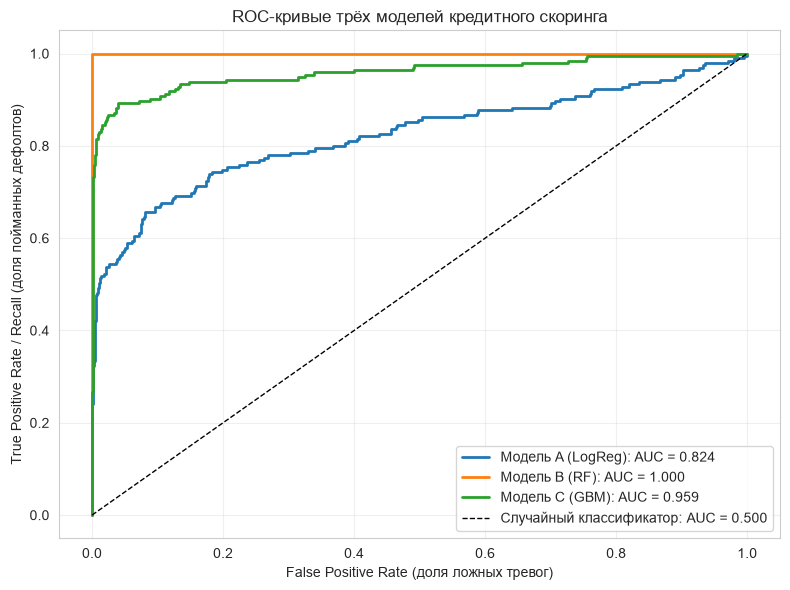

In [8]:
plt.figure(figsize=(8, 6))
for name, model in models.items():
    y_prob = model.predict_proba(X_test)[:, 1]
    fpr, tpr, _ = roc_curve(y_test, y_prob)
    auc = roc_auc_score(y_test, y_prob)
    plt.plot(fpr, tpr, linewidth=2, label=f'{name}: AUC = {auc:.3f}')

# Линия случайного классификатора
plt.plot([0, 1], [0, 1], 'k--', linewidth=1, label='Случайный классификатор: AUC = 0.500')

plt.xlabel('False Positive Rate (доля ложных тревог)')
plt.ylabel('True Positive Rate / Recall (доля пойманных дефолтов)')
plt.title('ROC-кривые трёх моделей кредитного скоринга')
plt.legend(loc='lower right')
plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()

### 3.3 Интерпретация ROC

> **TODO (5 баллов):** Какая модель показывает лучший AUC? Может ли высокий AUC скрывать проблемы? Приведите пример из этого задания.

**Ответ.**

Формально лучший AUC у **модели B — 1,000**, затем C — 0,959 и A — 0,824. Но AUC модели B — артефакт:
Random Forest обучался на `X, y`, то есть на всей выборке вместе с тестом, поэтому на тесте он
воспроизводит ответы, которые уже «видел». Кривая B идёт точно через точку (0, 1) — идеальный
классификатор, чего на реальных кредитных данных не бывает.

**Высокий AUC действительно может скрывать проблемы:**
1. **Утечку данных** — как в модели B: AUC 1,0 означает не качество, а попадание теста в обучение.
2. **Дисбаланс** — ROC-AUC считается по TPR и FPR и при 15 % дефолтов выглядит оптимистично; модель
   с AUC 0,96 может иметь Recall 0,80 на рабочем пороге. Для миноритарного класса информативнее PR-AUC.
3. **Плохую калибровку и неудачный порог** — AUC не зависит от порога, а бизнес работает с конкретным
   порогом: у A AUC 0,824, но Recall 0,46, потому что порог 0,5 смещён к мажоритарному классу.
4. **Переобучение** — у C ROC-AUC на train равен 1,0, а на кросс-валидации ≈ 0,966: высокий тестовый AUC
   не отменяет вопроса, насколько модель устойчива.

Вывод: AUC — necessary, but not sufficient. Смотреть на него нужно вместе с Recall/Precision на рабочем
пороге, матрицей ошибок и проверкой того, как модель обучалась.

---
## Часть 4. Диагностика проблем (25 баллов)

### 4.1 Дисбаланс классов

> **TODO (5 баллов):** Сравните долю предсказанных дефолтов с реальной. Затем обучите `LogisticRegression(class_weight='balanced')` и сравните Recall.

In [9]:
pred_a = model_a.predict(X_test)
print(f'Доля дефолтов — предсказанная: {pred_a.mean():.3f} | реальная: {y_test.mean():.3f}')

# Балансированная логистическая регрессия
model_a_bal = LogisticRegression(
    class_weight='balanced', random_state=42, max_iter=1000
).fit(X_train, y_train)
pred_a_bal = model_a_bal.predict(X_test)
prob_a_bal = model_a_bal.predict_proba(X_test)[:, 1]

print(f'\nLogReg без балансировки:')
print(f'  предсказанная доля дефолтов: {pred_a.mean():.3f}')
print(f'  Recall = {recall_score(y_test, pred_a):.4f}, '
      f'Precision = {precision_score(y_test, pred_a):.4f}, '
      f'F1 = {f1_score(y_test, pred_a):.4f}, '
      f'ROC-AUC = {roc_auc_score(y_test, model_a.predict_proba(X_test)[:, 1]):.4f}')

print(f'\nLogReg с class_weight="balanced":')
print(f'  предсказанная доля дефолтов: {pred_a_bal.mean():.3f}')
print(f'  Recall = {recall_score(y_test, pred_a_bal):.4f}, '
      f'Precision = {precision_score(y_test, pred_a_bal):.4f}, '
      f'F1 = {f1_score(y_test, pred_a_bal):.4f}, '
      f'ROC-AUC = {roc_auc_score(y_test, prob_a_bal):.4f}')

Доля дефолтов — предсказанная: 0.078 | реальная: 0.156

LogReg без балансировки:
  предсказанная доля дефолтов: 0.078
  Recall = 0.4615, Precision = 0.9278, F1 = 0.6164, ROC-AUC = 0.8235

LogReg с class_weight="balanced":
  предсказанная доля дефолтов: 0.280
  Recall = 0.7282, Precision = 0.4057, F1 = 0.5211, ROC-AUC = 0.8246


**Вывод 4.1.** Модель A предсказывает дефолт у **7,8 %** клиентов при реальных **15,6 %** — она занижает
частоту дефолтов примерно вдвое и систематически «недобирает» риск. Балансировка весов меняет картину:

| Вариант | Доля предсказанных дефолтов | Recall | Precision | F1 | ROC-AUC |
|---------|-----------------------------|--------|-----------|----|---------|
| LogReg | 0,078 | 0,462 | 0,928 | 0,616 | 0,824 |
| LogReg `class_weight='balanced'` | 0,280 | 0,728 | 0,406 | 0,521 | 0,825 |

Recall вырос с 0,462 до 0,728 (+26,6 п.п.) — модель ловит почти три четверти дефолтов. Цена — Precision
падает с 0,93 до 0,41: теперь 59 % отказов приходятся на клиентов, которые кредит вернули бы, а доля
предсказанных дефолтов (28 %) почти вдвое превышает реальную (15,6 %). ROC-AUC не изменился — балансировка
сдвигает порог, а не качество ранжирования. Выбор варианта — вопрос стоимости ошибок: если FN дороже FP,
balanced-версия или подбор порога по proba предпочтительнее «сырой» модели.

### 4.2 Утечка данных (Data Leakage)

> **TODO (10 баллов):** Сравните метрики Модели B на train и test. Объясните, что пошло не так и почему это критично для продакшна.

In [10]:
def metrics_row(model, X_, y_):
    pred = model.predict(X_)
    prob = model.predict_proba(X_)[:, 1]
    return {
        'Accuracy': accuracy_score(y_, pred),
        'Precision': precision_score(y_, pred, zero_division=0),
        'Recall': recall_score(y_, pred, zero_division=0),
        'F1': f1_score(y_, pred, zero_division=0),
        'ROC-AUC': roc_auc_score(y_, prob),
    }

leak_check = pd.DataFrame({
    'B — train (все данные)': metrics_row(model_b, X, y),
    'B — test': metrics_row(model_b, X_test, y_test),
}).T.round(4)
print('Модель B (обучена на X, y — с утечкой):')
print(leak_check)

# Как выглядела бы та же модель при корректном обучении только на train
model_b_fixed = RandomForestClassifier(n_estimators=100, random_state=42)
model_b_fixed.fit(X_train, y_train)
fixed_check = pd.DataFrame({
    'B_fixed — train': metrics_row(model_b_fixed, X_train, y_train),
    'B_fixed — test': metrics_row(model_b_fixed, X_test, y_test),
}).T.round(4)
print('\nМодель B, обученная только на X_train (без утечки):')
print(fixed_check)

cv_auc = cross_val_score(
    RandomForestClassifier(n_estimators=100, random_state=42),
    X, y, cv=5, scoring='roc_auc', n_jobs=-1
)
print(f'\nRF, 5-fold CV ROC-AUC на X: {cv_auc.mean():.4f} ± {cv_auc.std():.4f}')

Модель B (обучена на X, y — с утечкой):
                        Accuracy  Precision  Recall   F1  ROC-AUC
B — train (все данные)       1.0        1.0     1.0  1.0      1.0
B — test                     1.0        1.0     1.0  1.0      1.0



Модель B, обученная только на X_train (без утечки):
                 Accuracy  Precision  Recall      F1  ROC-AUC
B_fixed — train    1.0000     1.0000  1.0000  1.0000   1.0000
B_fixed — test     0.9496     0.9648  0.7026  0.8131   0.9512



RF, 5-fold CV ROC-AUC на X: 0.9558 ± 0.0114


**Вывод 4.2.**

| Обучение | Выборка | Accuracy | Precision | Recall | F1 | ROC-AUC |
|----------|---------|----------|-----------|--------|----|---------|
| `model_b.fit(X, y)` | train (все данные) | 1,0000 | 1,0000 | 1,0000 | 1,0000 | 1,0000 |
| `model_b.fit(X, y)` | test | 1,0000 | 1,0000 | 1,0000 | 1,0000 | 1,0000 |
| `fit(X_train, y_train)` | train | 1,0000 | 1,0000 | 1,0000 | 1,0000 | 1,0000 |
| `fit(X_train, y_train)` | test | 0,9496 | 0,9648 | 0,7026 | 0,8131 | 0,9512 |

**Что пошло не так.** Коллега обучил Random Forest на `X, y` — на **всей** выборке, включая тестовую часть.
Классический Random Forest на train и так даёт почти 1,0 (деревья запоминают объекты), поэтому идеальные
метрики на train никого не насторожили. Но тест перестал быть независимым: модель уже видела эти объекты
при обучении, и её 1,0 на тесте — не обобщение, а воспроизведение запомненных ответов. Это **утечка
данных (data leakage)**: нарушено ключевое правило — тестовая выборка не должна участвовать в обучении
и в подборе гиперпараметров.

Контрольный эксперимент это подтверждает: та же архитектура, обученная только на `X_train`, даёт на тесте
ROC-AUC 0,951, Recall 0,703, F1 0,813 — заметно хуже «идеальных» метрик B (разрыв по Recall и F1 —
20–30 п.п.). При этом 5-fold CV ROC-AUC честного Random Forest ≈ 0,956, то есть модель неплоха сама по
себе — но её настоящий уровень не 1,0.

**Почему это критично для продакшна.** В проде модель встретит только новые заявки, которых не было
в обучении. Метрики B (AUC 1,0, Recall 1,0) создают ложное ощущение, что риск полностью контролируется:
банк утвердит лимиты, цены и пороги, рассчитанные на несуществующее качество, и получит всплеск дефолтов
и потерь при первом же прогоне. Кроме того, утечка обычно означает и неправильный дизайн валидации
в целом — такую модель нельзя «чуть-чуть поправить», её нужно переобучать и заново валидировать на
чистом hold-out. В кредитном скоринге подобная ошибка — ещё и регуляторный риск: модели требуется
валидация и документирование, а результаты проверки на «загрязнённой» выборке недостоверны.

### 4.3 Переобучение

> **TODO (10 баллов):** Постройте кривые обучения для Модели C (`learning_curve`, `scoring='roc_auc'`, `cv=5`). По каким признакам на графике видно переобучение?

   train_size  train_auc  val_auc     gap
0         300        1.0   0.8470  0.1530
1         685        1.0   0.8708  0.1292
2        1071        1.0   0.9175  0.0825
3        1457        1.0   0.9550  0.0450
4        1842        1.0   0.9558  0.0442
5        2228        1.0   0.9613  0.0387
6        2614        1.0   0.9652  0.0348
7        3000        1.0   0.9657  0.0343


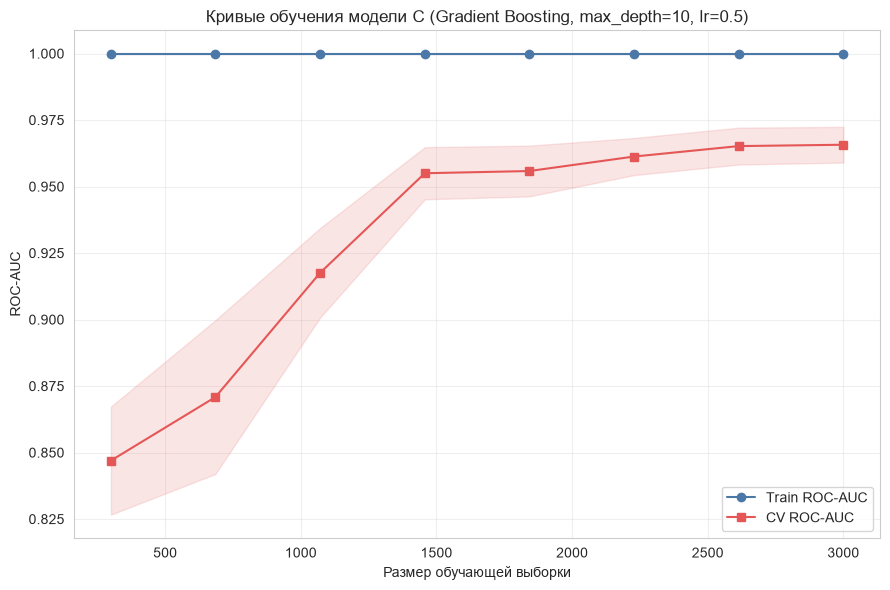

Train ROC-AUC на полном наборе: 1.0000
CV ROC-AUC на полном наборе:    0.9657
Разрыв train - CV:              0.0343
Train accuracy: 1.0000
Test accuracy:  0.9640


In [11]:
train_sizes, train_scores, val_scores = learning_curve(
    models['Модель C (GBM)'], X_train, y_train,
    cv=5, scoring='roc_auc', n_jobs=-1,
    train_sizes=np.linspace(0.1, 1.0, 8),
)

train_mean = train_scores.mean(axis=1)
train_std = train_scores.std(axis=1)
val_mean = val_scores.mean(axis=1)
val_std = val_scores.std(axis=1)

print(pd.DataFrame({
    'train_size': train_sizes.astype(int),
    'train_auc': train_mean.round(4),
    'val_auc': val_mean.round(4),
    'gap': (train_mean - val_mean).round(4),
}))

plt.figure(figsize=(9, 6))
plt.plot(train_sizes, train_mean, 'o-', color='#4C78A8', label='Train ROC-AUC')
plt.fill_between(train_sizes, train_mean - train_std, train_mean + train_std,
                 alpha=0.15, color='#4C78A8')
plt.plot(train_sizes, val_mean, 's-', color='#E45756', label='CV ROC-AUC')
plt.fill_between(train_sizes, val_mean - val_std, val_mean + val_std,
                 alpha=0.15, color='#E45756')
plt.xlabel('Размер обучающей выборки')
plt.ylabel('ROC-AUC')
plt.title('Кривые обучения модели C (Gradient Boosting, max_depth=10, lr=0.5)')
plt.legend(loc='lower right')
plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()

print(f'Train ROC-AUC на полном наборе: {train_mean[-1]:.4f}')
print(f'CV ROC-AUC на полном наборе:    {val_mean[-1]:.4f}')
print(f'Разрыв train - CV:              {train_mean[-1] - val_mean[-1]:.4f}')
print(f'Train accuracy: {accuracy_score(y_train, model_c.predict(X_train)):.4f}')
print(f'Test accuracy:  {accuracy_score(y_test, model_c.predict(X_test)):.4f}')

**Признаки переобучения.**

1. **Train ROC-AUC = 1,000 на всех размерах выборки** — модель идеально разделяет обучающие данные,
   но идеальное разделение на 5000 синтетических объектах означает запоминание, а не закономерность.
2. **Постоянный разрыв train и CV** — от 0,15 на 300 объектах до 0,034 на полном наборе: чем больше
   данных, тем меньше зазор, но он не исчезает; при 3000 объектов train 1,000 против CV 0,966.
3. **CV-кривая ещё растёт** — валидационный AUC повышается с 0,85 до 0,97 по мере добавления данных:
   модели не хватает не сложности, а данных, что типично для переобученной модели.
4. **Train accuracy = 1,000 против test 0,964** — та же картина на пороговой метрике.
5. **Гиперпараметры провоцируют переобучение**: `n_estimators=500` при `max_depth=10`, `learning_rate=0.5`
   и `min_samples_leaf=1` — глубокие деревья с высокой скоростью обучения, без early stopping
   и регуляризации; такие настройки рассчитаны на большие данные и легко запоминают шум.

Смягчение: уменьшить `max_depth` до 3–5, поднять `min_samples_leaf` (20–50), снизить `learning_rate`
до 0,05–0,1, добавить early stopping по валидации и `subsample < 1`; сверить улучшение на отдельном
hold-out, а не на train.

---
## Часть 5. Итоговое заключение (10 баллов)

### Сводная таблица проблем

| Модель | Проблема | Проявление | Критичность |
|--------|----------|------------|--------------|
| A — Logistic Regression | Дисбаланс классов: модель смещена к мажоритарному классу | Accuracy 0,910 при Recall по дефолтам 0,462: ловит меньше половины дефолтов, предсказывает дефолт у 7,8 % против реальных 15,6 %; `class_weight='balanced'` поднимает Recall до 0,728 | Высокая — пропускается ~54 % дефолтов, это прямые кредитные потери |
| B — Random Forest | Утечка данных: обучение на `X, y` вместе с тестовой выборкой | Идеальные метрики на train и test (Accuracy = Recall = F1 = ROC-AUC = 1,000); честная модель на `X_train` даёт на тесте AUC 0,951 и Recall 0,703 | Критическая — метрики недостоверны, модель нельзя запускать и нельзя использовать для решений |
| C — Gradient Boosting | Переобучение: слишком сложная модель без регуляризации | Train ROC-AUC = 1,000, CV ROC-AUC 0,966, train accuracy 1,000 против test 0,964; глубокие деревья (depth=10), lr=0,5, min_samples_leaf=1 | Средняя — лучшие честные тестовые метрики (F1 0,874, AUC 0,959), но запас обобщения невелик; нужна регуляризация и валидация |

### Рекомендация

**Ни одну из трёх моделей нельзя запускать в продакшн в текущем виде.**

1. **Модель B — отозвать.** Её метрики — артефакт утечки. Переобучить строго на `X_train`, тест держать
   «под замком» до финальной оценки, гиперпараметры подбирать только по кросс-валидации на train.
2. **Модель A — оставить как baseline и как «осторожный» вариант.** Если бизнес готов к Precision ≈ 0,93
   и потерям от пропущенных дефолтов, её можно использовать, но Recall 0,46 для скоринга, скорее всего,
   неприемлем. Вариант с `class_weight='balanced'` (Recall 0,728, Precision 0,406) — рабочий компромисс,
   если FN дороже FP; порог лучше подбирать по вероятности, а не брать 0,5.
3. **Модель C — основной кандидат на доработку.** У неё лучший баланс среди честных моделей
   (Precision 0,963 / Recall 0,800 / F1 0,874 / AUC 0,959). Перед запуском: уменьшить сложность
   (`max_depth` 3–5, `min_samples_leaf` 20–50, `learning_rate` 0,05–0,1, `subsample` 0,8, early stopping),
   подобрать порог под целевой Recall (например ≥ 0,7–0,8) с учётом стоимости FN/FP, откалибровать
   вероятности (`CalibratedClassifierCV`) и подтвердить качество на out-of-time выборке.
4. **Общие требования к запуску:** зафиксировать метрики и порог в модели-карте, настроить мониторинг
   Recall/FN, доли одобрений, PSI/дрейфа признаков, регулярно переобучать; проверить устойчивость метрик
   бутстрэпом и на нескольких временных срезах; провести проверку на смещения (fairness) по защищённым
   группам.

### Ключевые ограничения

- **Синтетические данные.** `make_classification` не воспроизводит реальные зависимости кредитного риска,
  пропуски, категориальные признаки и временную динамику; абсолютные значения метрик нельзя переносить
  на реальный портфель.
- **Один случайный сплит.** Метрики посчитаны на одном hold-out без доверительных интервалов; разница
  между моделями в 1–2 п.п. может быть в пределах шума.
- **Нет out-of-time валидации.** Для скоринга критично проверять модель на заявках более позднего периода:
  случайный сплит завышает качество при дрейфе.
- **Нет матрицы стоимости ошибок.** Вывод «FN критичнее FP» — качественный; для выбора порога нужны
  конкретные стоимости FN/FP и LGD.
- **Не оценивались калибровка, fairness и регуляторные требования**, хотя для кредитных моделей они
  обязательны.
- **Ограниченный набор метрик.** Не считались PR-AUC, Brier score, Lift/Gini, KS — стандартный набор
  для скоринга; выводы стоит дополнить ими.

---
## Итоговая сводка

| Модель | Accuracy | Precision | Recall | F1 | ROC-AUC | Диагноз |
|--------|----------|-----------|--------|----|---------|---------|
| A — LogReg | 0,910 | 0,928 | 0,462 | 0,616 | 0,824 | Дисбаланс: низкий Recall |
| B — RF | 1,000 | 1,000 | 1,000 | 1,000 | 1,000 | Утечка данных: метрики недостоверны |
| C — GBM | 0,964 | 0,963 | 0,800 | 0,874 | 0,959 | Переобучение: лучший честный результат |

**Рекомендация:** в прод не запускать ни одну модель; B — переобучить без утечки, C — регуляризовать,
откалибровать и подобрать порог под целевой Recall, A — использовать как baseline.